# 07 — LSTM and GRU forecasting of the aggregate series (Phase 3 · Step 2)

This notebook trains and evaluates two recurrent neural networks — **LSTM** (long short-term memory) and **GRU**
(gated recurrent unit) — on the one *aggregate* series of the project: the daily total of unit sales of store CA_1,
department FOODS_3 (the 823 products added together). It uses the **same five expanding development folds, the same
28-day horizon and the same metrics** as the Phase 2 classical models, and compares the networks with those models
using their *saved* forecasts (nothing is retyped).

* **Aggregate series only.** The item-level series are intermittent (many zero days) and are handled by notebook 05
  (Croston/TSB) and notebook 06 (XGBoost). Aggregate errors (thousands of units per day) and item-level errors (a few units
  per day) are on different scales and are never ranked against each other.
* **Final holdout.** The last 28 days (2016-04-25 → 2016-05-22) are reserved for one final evaluation. They are **not
  read, trained on, tuned on or reported anywhere in this notebook**; Section 6 checks this on the saved files.
* **No tuning.** Every setting comes from `config.yaml` (section `neural`) and was fixed *before* any result existed.
  The four variants (LSTM/GRU × calendar/univariate) are pre-declared there too.

## 1. Objective

*Can a small recurrent network forecast the next 28 days of aggregate daily sales better than the classical models of
Phase 2 (Seasonal Naive, ARIMA, SARIMA, Holt-Winters) when everything is evaluated the same way?*

The notebook answers a narrower, measurable question: **how do LSTM and GRU compare with the Phase 2 models on these five
development folds, in MAE, RMSE, zero-protected MAPE, WAPE and MASE — and how much does the result vary between folds
and between random seeds?** It deliberately does not claim a universal winner (see Section 9).

## 2. Method — what an LSTM/GRU forecaster does

### 2.1 Recurrent networks in one paragraph
A normal neural network sees all its inputs at once. A *recurrent* network reads a sequence **one day at a time** and keeps
a **hidden state**: a short vector of numbers that summarises everything it has read so far. After the last day of the input
window, the hidden state is a learned summary of the recent past (level, weekly rhythm, recent movement). A final linear
layer turns that summary into the forecast.

### 2.2 LSTM and GRU
Plain recurrent networks forget quickly because the learning signal fades over many steps. **LSTM** adds a *cell state*
(a long-term memory lane) and three *gates* — numbers between 0 and 1 computed from today's input and yesterday's hidden
state: the **forget gate** (how much old memory to keep), the **input gate** (how much new information to write) and the
**output gate** (how much memory to expose). **GRU** is a lighter variant with two gates (update and reset) and no
separate cell state, so it has fewer parameters. Both are used here with one layer of 32 units.

### 2.3 Sliding windows
The series is cut into overlapping training samples. For a day *t*: **input** = the sales of days *t−55 … t* (56 days),
**target** = the sales of days *t+1 … t+28*. Moving *t* forward one day at a time produces one sample per day. A sample
is only built if *both* its input and its target lie inside the fold's training history (Section 3 shows this on real dates).

### 2.4 Direct multi-horizon forecasting (no recursion)
A *recursive* forecaster predicts tomorrow, feeds that prediction back as an input, predicts the day after, and so on — errors
compound and a forecast becomes an input. Here one forward pass emits **all 28 future days at once** (a *direct*
forecaster). Nothing predicted is ever fed back, and no actual future sales value can enter a prediction.

### 2.5 Two information sets (the four variants)
| Variant | What the network sees |
|---|---|
| `calendar` | the past 56 days of sales **plus calendar facts that are published in advance**: day of week, SNAP-benefit day (CA), M5 event types (cultural, national, religious, sporting) and the Christmas closure — for the past days *and* for the 28 days being forecast |
| `univariate` | the past 56 days of sales only — the same information set as the Phase 2 classical models |

Comparing the two tells us whether the extra, legitimately-known calendar information helps. Calendar flags are 0/1 facts,
never sales, and a date missing from the calendar raises an error instead of being filled with zeros.

### 2.6 Scaling, loss, optimiser, early stopping, seeds
* **Scaling.** Sales are standardised, (x − mean) / std, with the mean and std of the **inner training part only** (see early
  stopping). The forecast window and the validation tail never influence the scaler.
* **Loss.** Huber loss (δ = 1 in standardised units): quadratic for small errors, linear for large ones, so a handful of
  extreme days cannot dominate training.
* **Optimiser.** Adam, learning rate 0.002, batches of 64 samples, gradient-norm clipping at 1.0, dropout 0.1 on the last hidden state.
* **Early stopping.** The *last 56 days of each fold's training window* are held out as an **inner validation tail**. The
  network is trained on windows whose targets end *before* the tail; the validation loss on windows whose targets lie *inside*
  the tail decides when to stop (10 epochs without improvement) and which epoch's weights to keep. The fold's forecast
  window is never touched.
* **Seed ensemble.** Five networks (seeds 0–4) are trained per fold and variant; the **reported forecast is their mean**, and
  the five individual forecasts are kept to show seed-to-seed variability.
* **Non-negativity.** Unit sales cannot be negative, so forecasts are **clipped at zero** after inverse scaling
  (`max(forecast, 0)`); the number of values this changes is reported per fit.
* **CPU-friendly.** One layer, 32 units, one thread, at most 80 epochs per network — it runs on a laptop CPU.

## 3. Setup and reproducibility

Run this notebook from the project root with
`python -m jupyter nbconvert --to notebook --execute --inplace notebooks/07_lstm_gru.ipynb`
(about 20–40 minutes on a laptop CPU; interrupted runs resume from checkpoints), or open it in VS Code / Jupyter and run all cells. It needs PyTorch
(`python -m pip install torch`, or `python -m pip install -r requirements-phase3.txt`) and the saved Phase 2 artifacts.

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Walk up from `start` until a directory containing config.yaml is found."""
    for candidate in [start, *start.parents]:
        if (candidate / "config.yaml").exists():
            return candidate
    raise FileNotFoundError(
        f"Could not find config.yaml in any parent directory of '{start}'. Run this notebook from within the project."
    )


PROJECT_ROOT = _find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT))

import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data.aggregate_series import load_aggregate_development
from src.evaluation.backtesting import generate_rolling_origins, run_backtest, summarize_backtest
from src.evaluation.forecast_artifacts import (
    audit_forecast_table,
    backtest_results_to_forecast_table,
    expected_fold_windows,
    fold_training_scales,
    load_aggregate_forecast_tables,
    metrics_by_group,
    read_forecast_table,
    write_forecast_table,
)
from src.models.lstm_gru import (
    NeuralConfig,
    NeuralSequenceForecaster,
    Scaler,
    build_windows,
    checkpoint_fingerprint,
    load_checkpoint,
    save_checkpoint,
    split_origins,
    variants_from_config,
)
from src.models.xgboost_model import load_event_calendar
from src.utils.config import load_config
from src.utils.provenance import build_run_metadata, write_json

try:
    import torch
except ImportError as exc:  # a clear message instead of a stack trace
    raise ImportError(
        "This notebook needs PyTorch. Install it with:  python -m pip install torch  "
        "(or: python -m pip install -r requirements-phase3.txt)"
    ) from exc

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.WARNING)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

config = load_config()
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__, "| torch", torch.__version__)
print("Backtest settings:", config["backtest"])
print("Neural settings :", {k: v for k, v in config["neural"].items() if k != "variants"})

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | torch 2.15.0+cu132
Backtest settings: {'holdout_days': 28, 'horizon': 28, 'n_folds': 5, 'season_length': 7}
Neural settings : {'input_window': 56, 'hidden_size': 32, 'num_layers': 1, 'dropout': 0.1, 'learning_rate': 0.002, 'weight_decay': 0.0, 'batch_size': 64, 'max_epochs': 80, 'patience': 10, 'validation_days': 56, 'loss': 'huber', 'huber_delta': 1.0, 'grad_clip': 1.0, 'seeds': [0, 1, 2, 3, 4], 'torch_num_threads': 1, 'primary_features': 'calendar'}


In [2]:
forecasts_dir = PROJECT_ROOT / config["phase3"]["forecasts_dir"]
metrics_dir = PROJECT_ROOT / config["phase3"]["metrics_dir"]
reports_dir = PROJECT_ROOT / config["reports"]["phase3_dir"]
for directory in (forecasts_dir, metrics_dir, reports_dir):
    directory.mkdir(parents=True, exist_ok=True)
p3 = config["phase3"]

# The ONLY way this notebook gets the series: the development period, holdout already cut off.
series, window = load_aggregate_development(config)
HORIZON, N_FOLDS = config["backtest"]["horizon"], config["backtest"]["n_folds"]
print(f"Development series: {len(series)} days, {series.index[0].date()} -> {series.index[-1].date()}  (aggregate daily unit sales)")
print(f"Reserved final holdout: {window.holdout_start.date()} -> {window.holdout_end.date()} ({window.n_holdout_days} days) -- dates only; its values are not loaded here.")

windows = expected_fold_windows(series.index, HORIZON, N_FOLDS)
print("\nThe five expanding development folds (identical to Phase 2):")
print(windows.assign(**{c: windows[c].dt.date for c in ("origin_date", "forecast_start", "forecast_end")}).to_string(index=False))

panel_path = PROJECT_ROOT / config["data"]["interim_dir"] / config["output"]["panel_filename"]
calendar = load_event_calendar(panel_path, last_date=window.dev_end)   # calendar columns only; read-time date filter
print(f"\nEvent calendar: {len(calendar)} days, {calendar.index.min().date()} -> {calendar.index.max().date()}; flags: {list(calendar.columns)}")
assert calendar.index.max() <= window.dev_end

ncfg = NeuralConfig.from_config(config)
VARIANTS = variants_from_config(config)
assert len(VARIANTS) == 4, "this notebook has one experiment cell per pre-declared variant"
print("\nPre-declared variants:", [v.name for v in VARIANTS])
print(f"Each (variant, fold) trains {len(ncfg.seeds)} networks (seeds {list(ncfg.seeds)}) -> {len(VARIANTS) * N_FOLDS * len(ncfg.seeds)} networks in total.")

Development series: 1913 days, 2011-01-29 -> 2016-04-24  (aggregate daily unit sales)
Reserved final holdout: 2016-04-25 -> 2016-05-22 (28 days) -- dates only; its values are not loaded here.

The five expanding development folds (identical to Phase 2):
 fold  n_train origin_date forecast_start forecast_end
    1     1773  2015-12-06     2015-12-07   2016-01-03
    2     1801  2016-01-03     2016-01-04   2016-01-31
    3     1829  2016-01-31     2016-02-01   2016-02-28
    4     1857  2016-02-28     2016-02-29   2016-03-27
    5     1885  2016-03-27     2016-03-28   2016-04-24



Event calendar: 1913 days, 2011-01-29 -> 2016-04-24; flags: ['snap_ca', 'event_cultural', 'event_national', 'event_religious', 'event_sporting', 'is_christmas']

Pre-declared variants: ['LSTM(calendar)', 'GRU(calendar)', 'LSTM(univariate)', 'GRU(univariate)']
Each (variant, fold) trains 5 networks (seeds [0, 1, 2, 3, 4]) -> 100 networks in total.


## 4. Leakage and alignment check on real dates

Before any training, this section shows — on fold 5's real calendar — exactly which days feed training, early stopping and
scaling. The assertions would fail if any sample read a day it should not.

In [3]:
fold = 5
row = windows.loc[windows["fold"] == fold].iloc[0]
train = series.iloc[: int(row.n_train)]
values, dates = train.to_numpy(), train.index
W, H, V = ncfg.input_window, ncfg.horizon, ncfg.validation_days
train_origins, val_origins = split_origins(len(train), W, H, V)
tail_start = len(train) - V

print(f"Fold {fold}: training history {dates[0].date()} -> {dates[-1].date()} ({len(train)} days); forecast window {row.forecast_start.date()} -> {row.forecast_end.date()}")
print(f"Inner validation tail (the last {V} training days, used ONLY for early stopping): {dates[tail_start].date()} -> {dates[-1].date()}")
print(f"Training samples  : {len(train_origins)}  | first input day {dates[train_origins[0] - W + 1].date()}, last TARGET day {dates[train_origins[-1] + H].date()}")
print(f"Validation samples: {len(val_origins)}  | first target day {dates[val_origins[0] + 1].date()}, last target day {dates[val_origins[-1] + H].date()}")
one = train_origins[len(train_origins) // 2]
print(f"One training sample: input days {dates[one - W + 1].date()} -> {dates[one].date()} ({W} days), target days {dates[one + 1].date()} -> {dates[one + H].date()} ({H} days)")

assert dates[train_origins[-1] + H] < dates[tail_start], "a training target reached into the validation tail"
assert dates[val_origins[0] + 1] == dates[tail_start] and dates[val_origins[-1] + H] == dates[-1]
assert dates[-1] < row.forecast_start, "the history overlaps the forecast window"

scaler = Scaler.fit(values[:tail_start])
scaler_whole = Scaler.fit(values)
print(f"\nScaler fitted on the inner-train part ({dates[0].date()} -> {dates[tail_start - 1].date()}): mean {scaler.mean:.1f}, std {scaler.scale:.1f}")
print(f"(For comparison, the whole training window would give mean {scaler_whole.mean:.1f}, std {scaler_whole.scale:.1f} -- these are NOT used.)")

# Perturbation test: changing the validation-tail values must change neither the training samples nor the scaler.
perturbed = values.copy()
perturbed[tail_start:] += 1_000_000.0
for original, changed in zip(build_windows(scaler.transform(values), None, train_origins, W, H),
                             build_windows(scaler.transform(perturbed), None, train_origins, W, H)):
    assert np.array_equal(original, changed)
assert Scaler.fit(perturbed[:tail_start]) == scaler
print("Perturbation test passed: adding 1,000,000 to every validation-tail value changes no training sample and not the scaler.")
print("The fold's forecast window and every later day are never passed to `fit` at all (the model receives `series.iloc[:n_train]`).")

Fold 5: training history 2011-01-29 -> 2016-03-27 (1885 days); forecast window 2016-03-28 -> 2016-04-24
Inner validation tail (the last 56 training days, used ONLY for early stopping): 2016-02-01 -> 2016-03-27
Training samples  : 1746  | first input day 2011-01-29, last TARGET day 2016-01-31
Validation samples: 29  | first target day 2016-02-01, last target day 2016-03-27
One training sample: input days 2013-06-20 -> 2013-08-14 (56 days), target days 2013-08-15 -> 2013-09-11 (28 days)

Scaler fitted on the inner-train part (2011-01-29 -> 2016-01-31): mean 2050.1, std 561.3
(For comparison, the whole training window would give mean 2051.0, std 557.9 -- these are NOT used.)
Perturbation test passed: adding 1,000,000 to every validation-tail value changes no training sample and not the scaler.
The fold's forecast window and every later day are never passed to `fit` at all (the model receives `series.iloc[:n_train]`).


## 5. The experiment: 4 variants × 5 folds × 5 seeds

Each fold is run through the project's own `run_backtest` loop (a fresh model per fold, fitted on that fold's training
prefix only). A fit that fails is *recorded* with its error — never dropped and never replaced by another method.

**Resumable.** Training takes a while, so every finished (variant, fold) is saved to `artifacts/models/lstm_gru_checkpoints/`
(git-ignored). If the run is interrupted, execute the notebook again: a fold is restored only when a fingerprint of the neural
settings, the horizon, that fold's exact training values and the numpy / torch versions matches, and the printed line per
variant says how many folds were restored. Delete the folder to retrain everything from scratch.

In [4]:
runs = {}
CHECKPOINT_DIR = PROJECT_ROOT / p3["neural_checkpoint_dir"]


def run_variant(variant):
    """Backtest one pre-declared variant on all five folds; keep the model objects for diagnostics.

    Each fold is run through the project's own `run_backtest` on the series cut at that fold's forecast end, which is exactly
    that fold's training prefix plus its 28-day test window. A finished fold is saved to the checkpoint folder; a fold whose
    checkpoint matches the current settings, training data and library versions is restored instead of retrained.
    """
    results, instances, fold_seconds, restored = [], [], [], 0
    values = series.to_numpy(dtype=float)
    for origin in generate_rolling_origins(len(series), horizon=HORIZON, n_folds=N_FOLDS):
        fingerprint = checkpoint_fingerprint(config, variant.name, origin.fold, values[: origin.train_end])
        saved = load_checkpoint(CHECKPOINT_DIR, variant.name, origin.fold, fingerprint)
        if saved is not None:
            results.append(saved["result"]); instances.append(saved["model"]); fold_seconds.append(saved["seconds"]); restored += 1
            continue
        built = []

        def factory():
            model = NeuralSequenceForecaster.from_config(variant.cell, variant.features, config, calendar=calendar)
            built.append(model)
            return model

        started = time.perf_counter()
        result = run_backtest(series.iloc[: origin.test_end], factory, horizon=HORIZON, n_folds=1)[0]
        result.fold = origin.fold
        seconds = time.perf_counter() - started
        model = built[-1] if built else None
        save_checkpoint(CHECKPOINT_DIR, variant.name, origin.fold, fingerprint, result, model, seconds)
        results.append(result); instances.append(model); fold_seconds.append(seconds)
    seconds = float(sum(fold_seconds))
    runs[variant.name] = {"results": results, "instances": instances, "seconds": seconds, "restored_folds": restored}
    failed = [r for r in results if not r.success]
    epochs = [e for r in results if r.success for e in r.diagnostics["epochs_run"]]
    print(f"{variant.name:18s} folds ok {len(results) - len(failed)}/{len(results)} | {seconds / 60:5.1f} min training time | "
          f"{restored} of {len(results)} folds restored from checkpoint | epochs per network: "
          f"min {min(epochs) if epochs else '-'}, median {int(np.median(epochs)) if epochs else '-'}, max {max(epochs) if epochs else '-'}")
    for r in failed:
        print(f"   FAILED fold {r.fold}: {r.error}")


run_variant(VARIANTS[0])

LSTM(calendar)     folds ok 5/5 |   3.6 min training time | 5 of 5 folds restored from checkpoint | epochs per network: min 14, median 40, max 80


In [5]:
run_variant(VARIANTS[1])

GRU(calendar)      folds ok 5/5 |   7.4 min training time | 5 of 5 folds restored from checkpoint | epochs per network: min 11, median 33, max 80


In [6]:
run_variant(VARIANTS[2])

LSTM(univariate)   folds ok 5/5 |   2.8 min training time | 4 of 5 folds restored from checkpoint | epochs per network: min 13, median 31, max 70


In [7]:
run_variant(VARIANTS[3])

GRU(univariate)    folds ok 5/5 |   7.4 min training time | 0 of 5 folds restored from checkpoint | epochs per network: min 12, median 33, max 71


### 5.1 Assembling and saving the artifacts

In [8]:
forecast_frames, metric_frames, seed_rows, history_frames, diagnostic_rows = [], [], [], [], []
for name, run in runs.items():
    table = backtest_results_to_forecast_table(run["results"])
    spread = []
    for result, model in zip(run["results"], run["instances"]):
        if not result.success:
            spread.extend([np.nan] * len(result.dates))
            continue
        members = model.seed_predictions()                       # (n_seeds, horizon), zero-clipped, original units
        spread.extend(members.std(axis=0, ddof=0).tolist())
        for seed, member in zip(model.fit_diagnostics()["seeds"], members):
            errors = member - result.actuals
            seed_rows.append({"model": name, "fold": result.fold, "seed": seed,
                              "MAE": float(np.abs(errors).mean()), "RMSE": float(np.sqrt((errors ** 2).mean()))})
        log = model.training_history()
        log.insert(0, "fold", result.fold)
        log.insert(0, "model", name)
        history_frames.append(log)
        d = result.diagnostics
        for i, seed in enumerate(d["seeds"]):
            diagnostic_rows.append({
                "model": name, "fold": result.fold, "seed": seed, "n_obs": d["n_obs"], "history_end": d["history_end"],
                "n_train_windows": d["n_train_windows"], "n_validation_windows": d["n_validation_windows"],
                "scaler_mean": d["scaler_mean"], "scaler_scale": d["scaler_scale"], "scaler_fit_end_date": d["scaler_fit_end_date"],
                "epochs_run": d["epochs_run"][i], "best_epoch": d["best_epoch"][i], "best_val_loss": d["best_val_loss"][i],
                "final_train_loss": d["final_train_loss"][i], "stopped_early": d["stopped_early"][i],
                "hit_max_epochs": d["hit_max_epochs"][i], "fit_seconds": d["member_fit_seconds"][i],
            })
    table["predicted_std_across_seeds"] = spread
    forecast_frames.append(table)
    metric_frames.append(summarize_backtest(run["results"]))

neural_table = pd.concat(forecast_frames, ignore_index=True)
neural_metrics = pd.concat(metric_frames, ignore_index=True)
seed_metrics = pd.DataFrame(seed_rows)
training_history = pd.concat(history_frames, ignore_index=True)
fit_diagnostics = pd.DataFrame(diagnostic_rows)

write_forecast_table(neural_table, forecasts_dir / p3["neural_forecasts_filename"])
neural_metrics.to_csv(metrics_dir / p3["neural_metrics_filename"], index=False, lineterminator="\n")
seed_metrics.to_csv(metrics_dir / p3["neural_seed_metrics_filename"], index=False, lineterminator="\n")
training_history.to_csv(metrics_dir / p3["neural_history_filename"], index=False, lineterminator="\n")
fit_diagnostics.to_csv(metrics_dir / p3["neural_diagnostics_filename"], index=False, lineterminator="\n")

total_minutes = sum(run["seconds"] for run in runs.values()) / 60
metadata = build_run_metadata(
    "lstm_gru", config=config, config_keys=["neural", "backtest"],
    extra={
        "variants": [v.name for v in VARIANTS], "seeds": list(ncfg.seeds), "folds": N_FOLDS, "horizon": HORIZON,
        "networks_trained": int(len(fit_diagnostics)), "failed_folds": int((~neural_metrics["success"]).sum()),
        "wall_minutes_total": round(total_minutes, 1),
        "folds_restored_from_checkpoint": int(sum(run["restored_folds"] for run in runs.values())),
        "wall_minutes_by_variant": {k: round(v["seconds"] / 60, 1) for k, v in runs.items()},
        "torch_threads": ncfg.torch_num_threads, "device": "cpu",
        "development_end": str(window.dev_end.date()),
    },
)
write_json(metrics_dir / p3["neural_metadata_filename"], metadata)

print(f"Forecast table : {len(neural_table)} rows -> {p3['neural_forecasts_filename']}")
print(f"Metrics table  : {len(neural_metrics)} rows -> {p3['neural_metrics_filename']}")
print(f"Seed metrics   : {len(seed_metrics)} rows -> {p3['neural_seed_metrics_filename']}")
print(f"Training log   : {len(training_history)} epoch rows -> {p3['neural_history_filename']}")
print(f"Fit diagnostics: {len(fit_diagnostics)} networks -> {p3['neural_diagnostics_filename']}")
print(f"Run metadata   : {p3['neural_metadata_filename']}")
restored_total = sum(run["restored_folds"] for run in runs.values())
print(f"Total training time: {total_minutes:.1f} minutes on {ncfg.torch_num_threads} thread(s); "
      f"{restored_total} of {sum(len(run['results']) for run in runs.values())} folds were restored from checkpoints (the rest trained in this run)")

Forecast table : 560 rows -> lstm_gru_backtest_forecasts.csv
Metrics table  : 20 rows -> lstm_gru_backtest_metrics.csv
Seed metrics   : 100 rows -> lstm_gru_seed_metrics.csv
Training log   : 3582 epoch rows -> lstm_gru_training_history.csv
Fit diagnostics: 100 networks -> lstm_gru_fit_diagnostics.csv
Run metadata   : lstm_gru_run_metadata.json
Total training time: 21.2 minutes on 1 thread(s); 14 of 20 folds were restored from checkpoints (the rest trained in this run)


## 6. Integrity checks

Every saved forecast table in this project passes the same audit: same folds and forecast windows as the protocol, actuals equal
to the development series, finite and non-negative predictions, and **no date after the end of the development period**.

In [9]:
saved = read_forecast_table(forecasts_dir / p3["neural_forecasts_filename"], "aggregate")
checks = audit_forecast_table(saved, kind="aggregate", dev_series=series, horizon=HORIZON, n_folds=N_FOLDS)
for c in checks:
    print(("PASS" if c.passed else "FAIL"), "-", c.name, "-", c.detail)
assert all(c.passed for c in checks)

n_expected = len(VARIANTS) * N_FOLDS * HORIZON
print(f"\nRows in the saved table: {len(saved)} (expected {n_expected}); models: {sorted(saved['model'].unique())}")
print("Failed (model, fold) fits:", int((~neural_metrics['success']).sum()), "of", len(neural_metrics))
print("Negative predictions in the saved table:", int((saved["predicted"] < 0).sum()))
clipped = sum(m.fit_diagnostics()["n_negative_values_clipped"]
              for run in runs.values() for r, m in zip(run["results"], run["instances"]) if r.success)
print("Forecast values changed by the clip-at-zero rule (summed over every network):", int(clipped))
print(f"Latest forecast date saved: {saved['date'].max().date()}  |  last development day: {window.dev_end.date()}  |  holdout starts: {window.holdout_start.date()}")
assert saved["date"].max() <= window.dev_end
print("Confirmed: no date in the reserved final holdout appears in the saved forecasts.")

# Determinism: re-fit ONE network (LSTM(calendar), fold 5, seed 0) and compare with the ensemble member that has the same seed.
first = VARIANTS[0]
one_seed = NeuralConfig(**{**ncfg.__dict__, "seeds": (ncfg.seeds[0],)})
repeat = NeuralSequenceForecaster(first.cell, first.features, one_seed, calendar=calendar).fit(series.iloc[: int(windows.n_train.iloc[-1])])
original_member = runs[first.name]["instances"][-1].seed_predictions()[0]
assert np.array_equal(repeat.predict(HORIZON), original_member)
print(f"Determinism: re-fitting {first.name}, fold {N_FOLDS}, seed {ncfg.seeds[0]} reproduces the saved member forecast bit for bit.")

PASS - no_dates_after_development_end - ok
PASS - no_duplicate_rows - 0 duplicated row(s)
PASS - folds_and_windows_match_protocol - ok
PASS - actuals_equal_development_series - ok
PASS - predictions_finite_on_successful_rows - 0 non-finite prediction(s)
PASS - predictions_non_negative - 0 negative prediction(s)

Rows in the saved table: 560 (expected 560); models: ['GRU(calendar)', 'GRU(univariate)', 'LSTM(calendar)', 'LSTM(univariate)']
Failed (model, fold) fits: 0 of 20
Negative predictions in the saved table: 0
Forecast values changed by the clip-at-zero rule (summed over every network): 0
Latest forecast date saved: 2016-04-24  |  last development day: 2016-04-24  |  holdout starts: 2016-04-25
Confirmed: no date in the reserved final holdout appears in the saved forecasts.


Determinism: re-fitting LSTM(calendar), fold 5, seed 0 reproduces the saved member forecast bit for bit.


## 7. Results

### 7.1 Metrics used
For actual sales *a* and forecast *f* over a fold's 28 forecast days:

* **MAE** = mean |a − f| and **RMSE** = √mean (a − f)² — in units/day of the aggregate series; RMSE punishes large misses more.
* **MAPE** = mean |a − f| / a **over days with a > 0**, in %. A day with zero actual sales (the Christmas closure falls in fold 1)
  cannot be expressed as a percentage, so it is **excluded and counted** (`mape_n_excluded`); MAPE is therefore a secondary metric.
* **WAPE** = Σ|a − f| / Σa: total absolute error relative to total sales; scale-free and defined whenever there is any demand.
* **MASE** = MAE / (mean |y_t − y_{t−7}| over the fold's *training* window), i.e. MAE relative to the in-sample error of a
  seasonal-naive forecast; below 1 means better than that in-sample benchmark. It is undefined (NaN) if that scale is zero.
* Every figure is **recomputed here from the saved (actual, predicted) pairs** with the project's own metric functions, and
  the neural numbers are checked against the metrics file that was just saved.

In [10]:
classical_names = [config["phase2"][k] for k in ("seasonal_naive_forecasts_filename", "arima_forecasts_filename",
                                                   "sarima_forecasts_filename", "holt_winters_forecasts_filename")]
classical_tables, problems = load_aggregate_forecast_tables(classical_names, config)
for filename, message in problems.items():
    print("MISSING / INVALID ARTIFACT:", message)
if problems:
    print("\nThe comparison below contains only the models whose artifacts exist; nothing is filled in for the others.")

scales = fold_training_scales(series, windows, lag=config["comparison"]["mase_seasonal_lag"])
scale_frame = pd.DataFrame({"fold": list(scales), "mase_scale": list(scales.values())})
classical_checks = {fn: [c.name for c in audit_forecast_table(t, kind="aggregate", dev_series=series) if not c.passed] for fn, t in classical_tables.items()}
print("Audit failures in the Phase 2 forecast files:", {k: v for k, v in classical_checks.items() if v} or "none")

combined = pd.concat(list(classical_tables.values()) + [saved.drop(columns=["predicted_std_across_seeds"])], ignore_index=True)
fold_metrics = metrics_by_group(combined, ["model", "fold"], scale_frame)

# The neural numbers recomputed here must equal the metrics file written by the experiment.
check = fold_metrics[fold_metrics["model"].isin(neural_metrics["model"])].merge(neural_metrics, on=["model", "fold"], suffixes=("", "_saved"))
assert np.allclose(check["MAE"], check["MAE_saved"], atol=1e-8) and np.allclose(check["RMSE"], check["RMSE_saved"], atol=1e-8)
print("Recomputed neural MAE/RMSE equal the saved metrics file for every (model, fold).")

CLASSICAL = [m for m in fold_metrics["model"].unique() if m not in set(neural_metrics["model"])]
NEURAL = list(neural_metrics["model"].unique())
print("Classical (Phase 2) models:", CLASSICAL)
print("Neural models             :", NEURAL)

Audit failures in the Phase 2 forecast files: none
Recomputed neural MAE/RMSE equal the saved metrics file for every (model, fold).
Classical (Phase 2) models: ['SeasonalNaive', 'ARIMA(6, 1, 1)', 'SARIMA(6, 1, 1)x(0, 0, 2, 7)', 'HoltWinters(trend=add)']
Neural models             : ['LSTM(calendar)', 'GRU(calendar)', 'LSTM(univariate)', 'GRU(univariate)']


In [11]:
def fold_table(metric):
    pivot = fold_metrics.pivot(index="model", columns="fold", values=metric)
    pivot.columns = [f"fold {c}" for c in pivot.columns]
    pivot["mean"] = pivot.mean(axis=1)
    pivot["std (folds)"] = fold_metrics.pivot(index="model", columns="fold", values=metric).std(axis=1, ddof=1)
    return pivot.reindex(CLASSICAL + NEURAL)


print("MAE by fold (units/day, aggregate series) -- rows in a fixed order: Phase 2 models, then the neural variants")
print(fold_table("MAE").round(1).to_string())
print("\nRMSE by fold (units/day)")
print(fold_table("RMSE").round(1).to_string())

MAE by fold (units/day, aggregate series) -- rows in a fixed order: Phase 2 models, then the neural variants


                              fold 1  fold 2  fold 3  fold 4  fold 5   mean  std (folds)
model                                                                                   
SeasonalNaive                  253.4   323.9   289.1   189.6   226.7  256.6         52.4
ARIMA(6, 1, 1)                 217.3   323.1   244.8   219.8   223.1  245.6         44.7
SARIMA(6, 1, 1)x(0, 0, 2, 7)   269.8   314.9   237.1   164.7   153.3  228.0         68.8
HoltWinters(trend=add)         270.1   249.6   167.3   143.5   136.2  193.3         62.2
LSTM(calendar)                 231.2   217.6   168.9   165.4   125.0  181.6         42.9
GRU(calendar)                  224.1   289.9   185.6   167.4   129.6  199.3         61.0
LSTM(univariate)               277.1   314.9   166.0   160.3   130.1  209.7         81.0
GRU(univariate)                278.7   285.1   174.7   148.7   128.5  203.1         73.8

RMSE by fold (units/day)
                              fold 1  fold 2  fold 3  fold 4  fold 5   mean  std (fo

In [12]:
summary = (
    fold_metrics.groupby("model")
    .agg(MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"), RMSE_mean=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
         MAPE_mean_pct=("MAPE", "mean"), WAPE_mean=("WAPE", "mean"), MASE_mean=("MASE", "mean"), bias_mean=("bias", "mean"),
         folds_scored=("success", "sum"))
    .reindex(CLASSICAL + NEURAL)
)
summary.insert(0, "family", ["classical (Phase 2)"] * len(CLASSICAL) + ["neural (this notebook)"] * len(NEURAL))
excluded = fold_metrics.groupby("model")["mape_n_excluded"].sum().reindex(summary.index)
summary["zero_days_excluded_from_MAPE"] = excluded
print("Mean over the five development folds (std = sample standard deviation across the folds). Order is fixed, not a ranking.")
print(summary.round(3).to_string())
print("\nMAPE caveat: days with zero actual sales are excluded and counted above (the Christmas closure is in fold 1).")
print("bias = mean(forecast - actual); positive = over-forecast.")

Mean over the five development folds (std = sample standard deviation across the folds). Order is fixed, not a ranking.
                                              family  MAE_mean  MAE_std  RMSE_mean  RMSE_std  MAPE_mean_pct  WAPE_mean  MASE_mean  bias_mean  folds_scored  zero_days_excluded_from_MAPE
model                                                                                                                                                                                   
SeasonalNaive                    classical (Phase 2)   256.550   52.413    329.050    73.122         12.082      0.131      0.974    -79.179             5                             1
ARIMA(6, 1, 1)                   classical (Phase 2)   245.611   44.688    333.369    63.864         11.316      0.124      0.933    -45.591             5                             1
SARIMA(6, 1, 1)x(0, 0, 2, 7)     classical (Phase 2)   227.965   68.848    302.223    93.826         10.639      0.118      0.865    -86.529

### 7.2 Figures

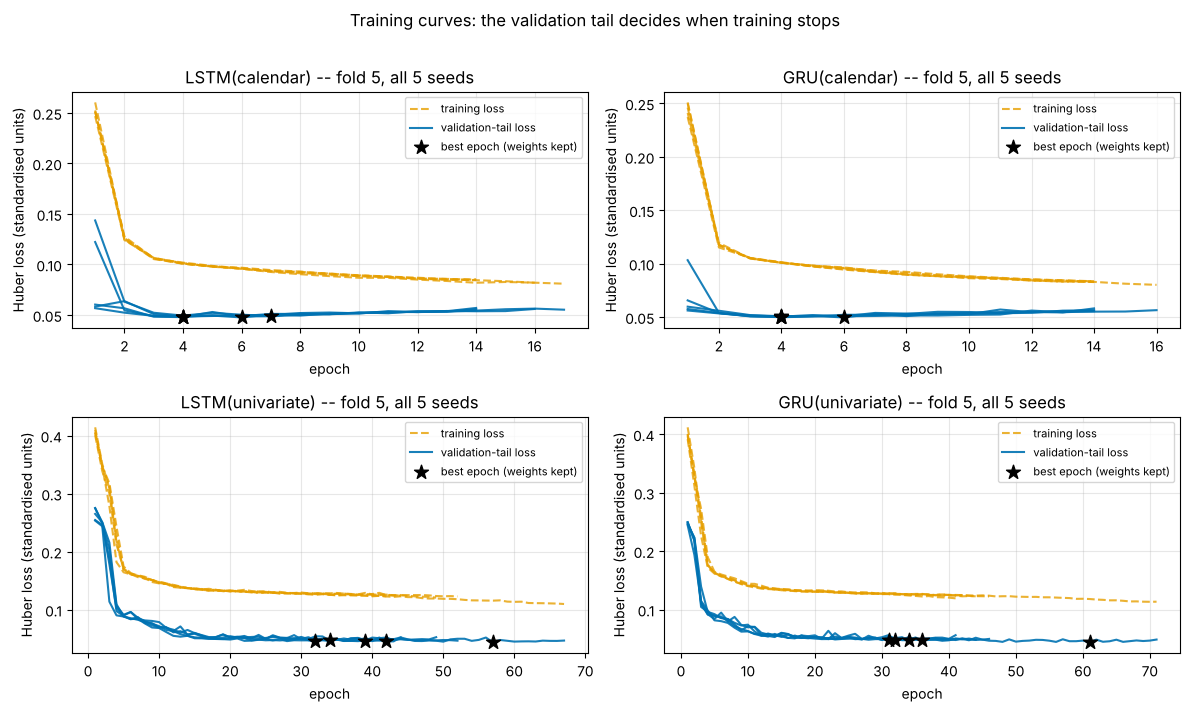

In [13]:
PALETTE = {"SeasonalNaive": "#666666", "ARIMA(6, 1, 1)": "#0072B2", "SARIMA(6, 1, 1)x(0, 0, 2, 7)": "#56B4E9",
           "HoltWinters(trend=add)": "#009E73", "LSTM(calendar)": "#D55E00", "GRU(calendar)": "#CC79A7",
           "LSTM(univariate)": "#E69F00", "GRU(univariate)": "#7A5C00"}
STYLES = {"SeasonalNaive": ":", "ARIMA(6, 1, 1)": "-.", "SARIMA(6, 1, 1)x(0, 0, 2, 7)": "--", "HoltWinters(trend=add)": "-.",
          "LSTM(calendar)": "-", "GRU(calendar)": "--", "LSTM(univariate)": "-", "GRU(univariate)": "--"}
MARKERS = {"LSTM(calendar)": "o", "GRU(calendar)": "s", "LSTM(univariate)": "^", "GRU(univariate)": "v"}


def save_figure(fig, filename):
    fig.savefig(reports_dir / filename, dpi=150, bbox_inches="tight")


# Figure 1: training and validation loss of the five seeds in the last fold, per variant.
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=False)
for ax, variant in zip(axes.ravel(), VARIANTS):
    log = training_history[(training_history["model"] == variant.name) & (training_history["fold"] == N_FOLDS)]
    for i, (seed, one) in enumerate(log.groupby("seed")):
        ax.plot(one["epoch"], one["train_loss"], linestyle="--", color="#E69F00", alpha=0.8, label="training loss" if i == 0 else None)
        ax.plot(one["epoch"], one["val_loss"], linestyle="-", color="#0072B2", alpha=0.9, label="validation-tail loss" if i == 0 else None)
        best = one[one["is_best_epoch"]]
        ax.scatter(best["epoch"], best["val_loss"], marker="*", s=110, color="black", zorder=5, label="best epoch (weights kept)" if i == 0 else None)
    ax.set_title(f"{variant.name} -- fold {N_FOLDS}, all {len(ncfg.seeds)} seeds")
    ax.set_xlabel("epoch")
    ax.set_ylabel("Huber loss (standardised units)")
    ax.legend(fontsize=8)
fig.suptitle("Training curves: the validation tail decides when training stops", y=1.01)
fig.tight_layout()
save_figure(fig, p3["neural_training_curves_plot_filename"])
plt.show()

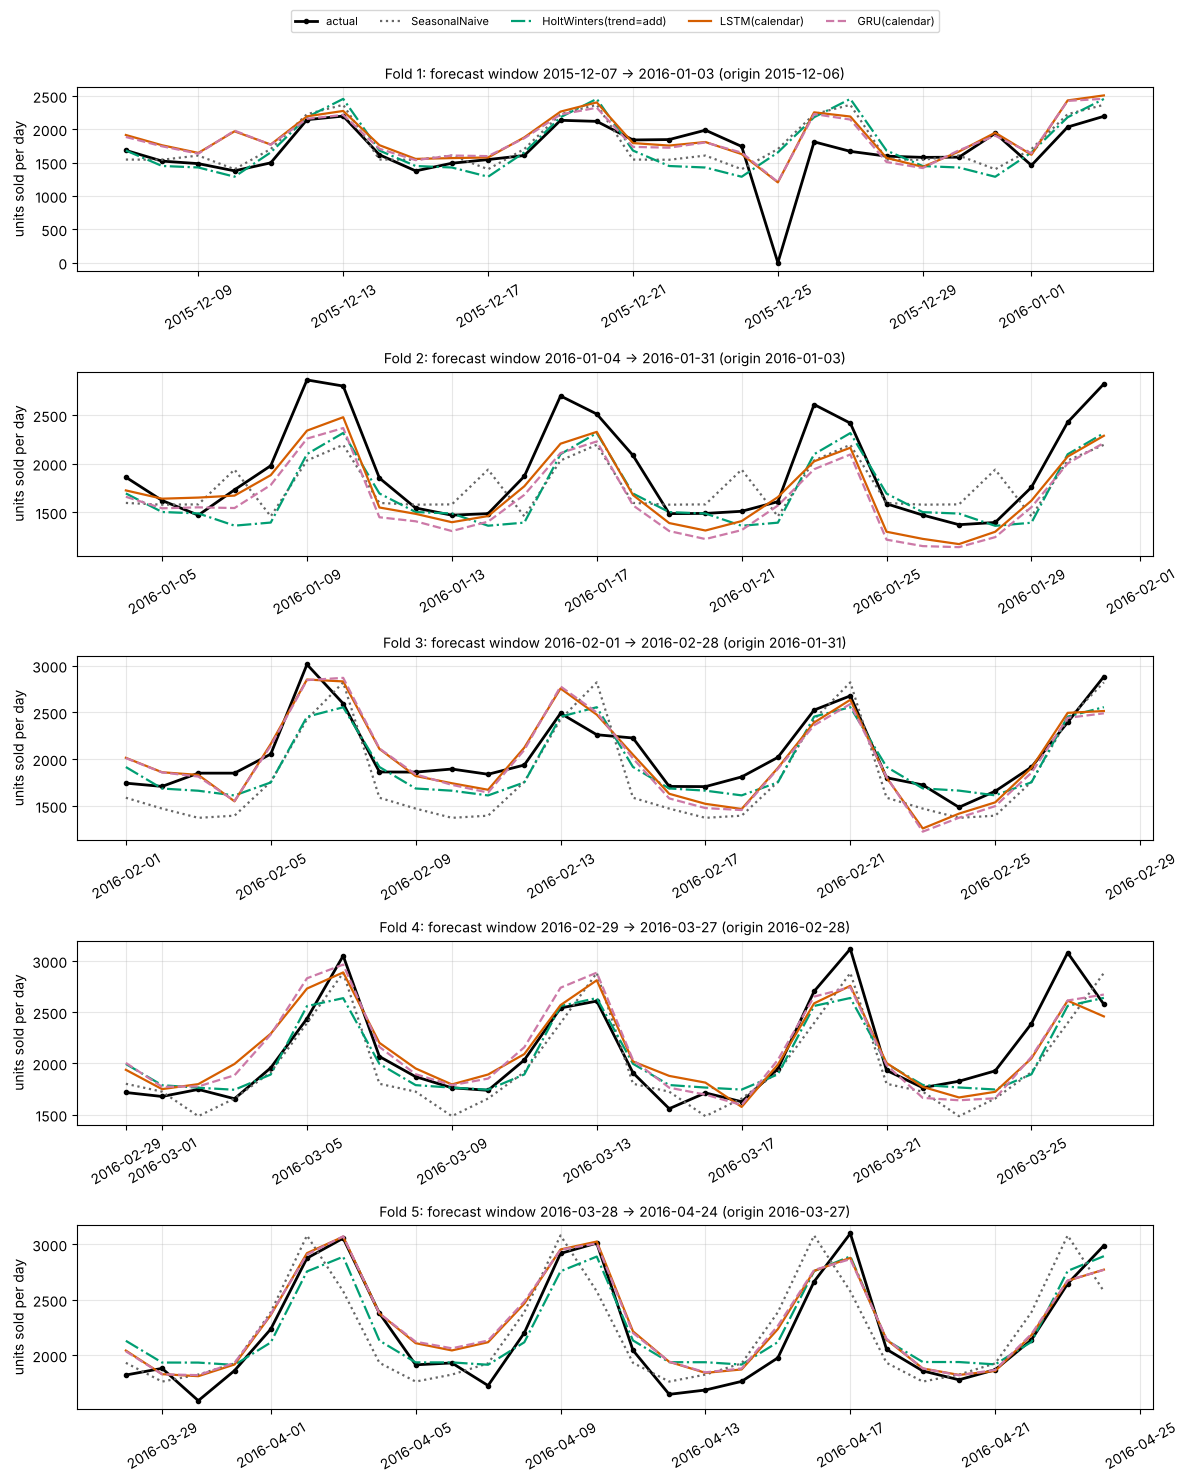

In [14]:
# Figure 2: actual vs forecast, one panel per fold: the actual series, the two calendar variants and two classical benchmarks.
shown = ["SeasonalNaive", "HoltWinters(trend=add)", "LSTM(calendar)", "GRU(calendar)"]
shown = [m for m in shown if m in set(combined["model"])]
fig, axes = plt.subplots(N_FOLDS, 1, figsize=(12, 3.0 * N_FOLDS), sharey=False)
for ax, (_, w) in zip(axes, windows.iterrows()):
    one = combined[combined["fold"] == w["fold"]]
    actual = one[one["model"] == shown[0]].sort_values("date")
    ax.plot(actual["date"], actual["actual"], color="black", linewidth=2.0, marker="o", markersize=3, label="actual")
    for model in shown:
        m = one[one["model"] == model].sort_values("date")
        ax.plot(m["date"], m["predicted"], linestyle=STYLES[model], color=PALETTE[model], linewidth=1.6, label=model)
    ax.set_title(f"Fold {int(w['fold'])}: forecast window {w['forecast_start'].date()} -> {w['forecast_end'].date()} (origin {w['origin_date'].date()})", fontsize=10)
    ax.set_ylabel("units sold per day")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.45))
fig.tight_layout()
save_figure(fig, p3["neural_forecast_plot_filename"])
plt.show()

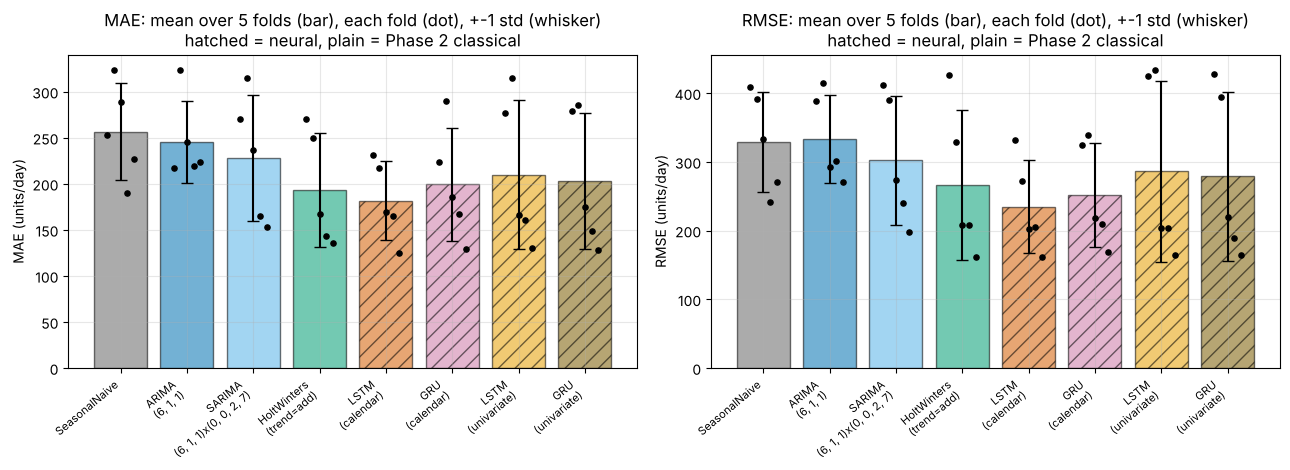

In [15]:
# Figure 3: MAE and RMSE -- mean over folds (bar, hatched = neural) with fold values (markers) and +-1 std error bars.
order = CLASSICAL + NEURAL
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    means = fold_metrics.groupby("model")[metric].mean().reindex(order)
    stds = fold_metrics.groupby("model")[metric].std().reindex(order)
    positions = np.arange(len(order))
    bars = ax.bar(positions, means.to_numpy(), yerr=stds.to_numpy(), capsize=4, color=[PALETTE[m] for m in order], alpha=0.55, edgecolor="black")
    for bar, model in zip(bars, order):
        if model in NEURAL:
            bar.set_hatch("//")
    for i, model in enumerate(order):
        values_by_fold = fold_metrics[fold_metrics["model"] == model].sort_values("fold")[metric].to_numpy()
        ax.scatter(np.full(len(values_by_fold), i) + np.linspace(-0.2, 0.2, len(values_by_fold)), values_by_fold, color="black", s=14, zorder=4)
    ax.set_xticks(positions)
    ax.set_xticklabels([m.replace("(", "\n(", 1) for m in order], rotation=40, ha="right", fontsize=8)
    ax.set_ylabel(f"{metric} (units/day)")
    ax.set_title(f"{metric}: mean over 5 folds (bar), each fold (dot), +-1 std (whisker)\nhatched = neural, plain = Phase 2 classical")
fig.tight_layout()
save_figure(fig, p3["neural_comparison_plot_filename"])
plt.show()

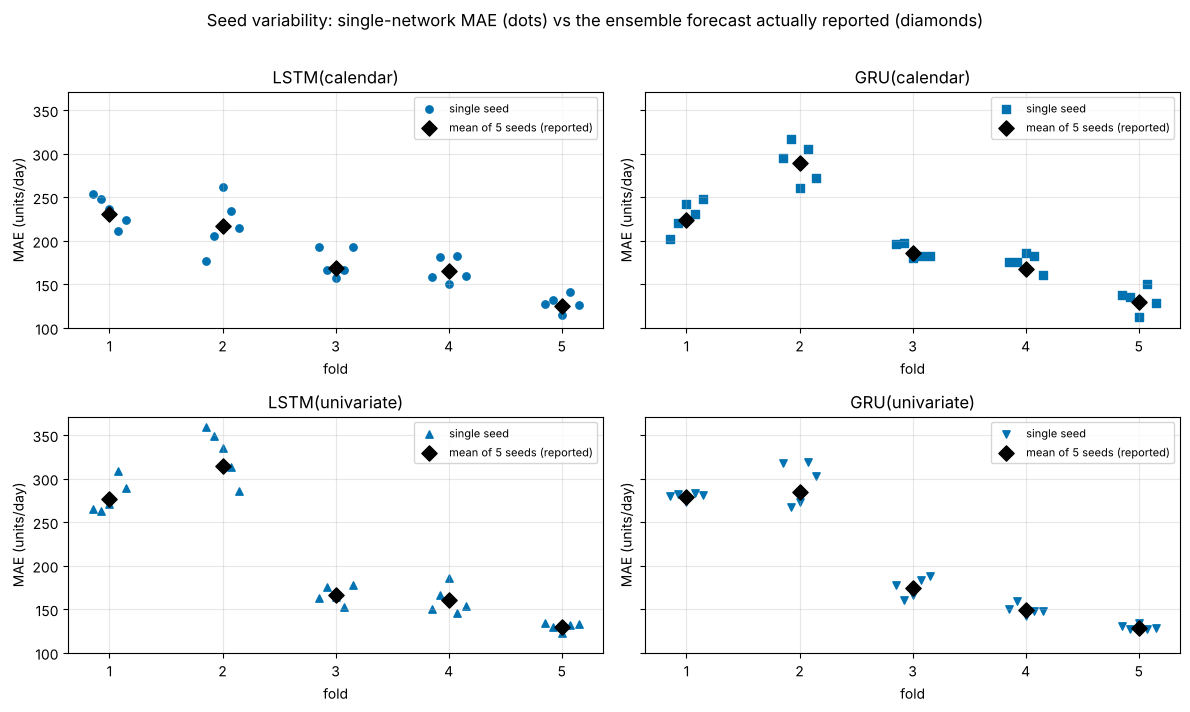

In [16]:
# Figure 4: how much does one random seed matter?  MAE of each seed's own forecast vs the ensemble mean's MAE.
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, variant in zip(axes.ravel(), VARIANTS):
    one = seed_metrics[seed_metrics["model"] == variant.name]
    ens = fold_metrics[fold_metrics["model"] == variant.name].set_index("fold")["MAE"]
    for fold_id, group in one.groupby("fold"):
        ax.scatter(np.full(len(group), fold_id) + np.linspace(-0.15, 0.15, len(group)), group["MAE"], color="#0072B2", s=28,
                   marker=MARKERS[variant.name], label="single seed" if fold_id == 1 else None)
    ax.scatter(ens.index, ens.to_numpy(), color="black", marker="D", s=60, zorder=5, label="mean of 5 seeds (reported)")
    ax.set_title(variant.name)
    ax.set_xlabel("fold")
    ax.set_ylabel("MAE (units/day)")
    ax.set_xticks(range(1, N_FOLDS + 1))
    ax.legend(fontsize=8)
fig.suptitle("Seed variability: single-network MAE (dots) vs the ensemble forecast actually reported (diamonds)", y=1.01)
fig.tight_layout()
save_figure(fig, p3["neural_seed_plot_filename"])
plt.show()

## 8. Interpretation (computed from the tables above)

The sentences below are printed by code, so they always match the numbers. They describe **these eight models on these five
development folds of one aggregate series**; they are not a final ranking, no significance test was run, and the final holdout
was not used.

In [17]:
mae_mean = fold_metrics.groupby("model")["MAE"].mean()
rmse_mean = fold_metrics.groupby("model")["RMSE"].mean()
mae_by_fold = fold_metrics.pivot(index="model", columns="fold", values="MAE")

best_overall = mae_mean.idxmin()
best_classical = mae_mean[CLASSICAL].idxmin() if CLASSICAL else None
best_neural = mae_mean[NEURAL].idxmin()
print(f"Lowest mean MAE among all {len(mae_mean)} models: {best_overall} ({mae_mean[best_overall]:.1f} units/day).")
if best_classical:
    gap = mae_mean[best_neural] - mae_mean[best_classical]
    print(f"Best neural variant ({best_neural}, {mae_mean[best_neural]:.1f}) vs best Phase 2 model ({best_classical}, {mae_mean[best_classical]:.1f}): "
          f"difference {gap:+.1f} units/day ({100 * gap / mae_mean[best_classical]:+.1f}%).")
    wins = int((mae_by_fold.loc[best_neural] < mae_by_fold.loc[best_classical]).sum())
    print(f"In {wins} of {N_FOLDS} folds {best_neural} had the lower MAE of the two.")
if "SeasonalNaive" in mae_mean.index:
    for model in NEURAL:
        beats = int((mae_by_fold.loc[model] < mae_by_fold.loc["SeasonalNaive"]).sum())
        print(f"  {model:18s} MAE below Seasonal Naive in {beats} of {N_FOLDS} folds (mean {mae_mean[model]:.1f} vs {mae_mean['SeasonalNaive']:.1f}).")

print("\nDoes the extra calendar information help? (same cell type, calendar vs univariate)")
for cell in ("LSTM", "GRU"):
    with_cal, without = f"{cell}(calendar)", f"{cell}(univariate)"
    diff = mae_mean[with_cal] - mae_mean[without]
    lower = int((mae_by_fold.loc[with_cal] < mae_by_fold.loc[without]).sum())
    print(f"  {cell}: mean MAE {mae_mean[with_cal]:.1f} with calendar vs {mae_mean[without]:.1f} without ({diff:+.1f}); calendar lower in {lower} of {N_FOLDS} folds.")

print("\nLSTM vs GRU (same information set)")
for features in ("calendar", "univariate"):
    a, b = f"LSTM({features})", f"GRU({features})"
    print(f"  {features:10s}: LSTM {mae_mean[a]:.1f} vs GRU {mae_mean[b]:.1f} (LSTM - GRU = {mae_mean[a] - mae_mean[b]:+.1f}); LSTM lower in {int((mae_by_fold.loc[a] < mae_by_fold.loc[b]).sum())} of {N_FOLDS} folds.")

print("\nVariation: spread of fold MAE (max - min) and of single-seed MAE")
for model in NEURAL:
    seeds = seed_metrics[seed_metrics["model"] == model]
    within_fold_range = seeds.groupby("fold")["MAE"].agg(lambda s: s.max() - s.min())
    ensemble_vs_members = np.mean([fold_metrics[(fold_metrics["model"] == model) & (fold_metrics["fold"] == f)]["MAE"].iloc[0] <= g["MAE"].mean()
                                   for f, g in seeds.groupby("fold")])
    print(f"  {model:18s} fold-to-fold MAE range {mae_by_fold.loc[model].max() - mae_by_fold.loc[model].min():6.1f} | "
          f"largest seed-to-seed MAE range within a fold {within_fold_range.max():6.1f} | "
          f"ensemble MAE <= mean single-seed MAE in {int(round(ensemble_vs_members * N_FOLDS))} of {N_FOLDS} folds")

print("\nBias (mean forecast - actual, units/day), averaged over folds:")
print(fold_metrics.groupby("model")["bias"].mean().reindex(CLASSICAL + NEURAL).round(1).to_string())
print("\nThese are descriptions of five folds. Differences between models are compared with fold-to-fold variation above; "
      "no significance test was performed and none is claimed.")

Lowest mean MAE among all 8 models: LSTM(calendar) (181.6 units/day).
Best neural variant (LSTM(calendar), 181.6) vs best Phase 2 model (HoltWinters(trend=add), 193.3): difference -11.7 units/day (-6.1%).
In 3 of 5 folds LSTM(calendar) had the lower MAE of the two.
  LSTM(calendar)     MAE below Seasonal Naive in 5 of 5 folds (mean 181.6 vs 256.6).
  GRU(calendar)      MAE below Seasonal Naive in 5 of 5 folds (mean 199.3 vs 256.6).
  LSTM(univariate)   MAE below Seasonal Naive in 4 of 5 folds (mean 209.7 vs 256.6).
  GRU(univariate)    MAE below Seasonal Naive in 4 of 5 folds (mean 203.1 vs 256.6).

Does the extra calendar information help? (same cell type, calendar vs univariate)
  LSTM: mean MAE 181.6 with calendar vs 209.7 without (-28.1); calendar lower in 3 of 5 folds.
  GRU: mean MAE 199.3 with calendar vs 203.1 without (-3.8); calendar lower in 1 of 5 folds.

LSTM vs GRU (same information set)
  calendar  : LSTM 181.6 vs GRU 199.3 (LSTM - GRU = -17.7); LSTM lower in 4 of 5 folds

## 9. Limitations

* **One series, five folds, 140 forecast days.** The aggregate series is a single time series; five 28-day windows give a noisy
  estimate, and fold-to-fold variation (Section 8) can be as large as the gaps between models. **No significance test was
  run**, so no model is declared significantly better.
* **Small, fixed networks.** One layer, 32 units, fixed learning rate and window — a documented starting point, *not* an optimum.
  No hyper-parameter search was run (it would have to be nested inside each training window, which is a later step).
* **Different information sets.** The `calendar` variants use extra published-in-advance information that the Phase 2 classical
  models do not use; the `univariate` variants use the same information as those models. Differences between families mix the
  model class with the information set — compare like with like (Section 8).
* **Seeds.** Neural results depend on random initialisation; the five-seed mean reduces but does not remove that variation
  (Figure 4). Bit-exact reproducibility holds on one machine and library version; another operating system, CPU or PyTorch
  version can differ in the last digits.
* **MAPE** drops zero-sales days (the Christmas closure); it is shown but is not the basis of any statement here.
* **Direct 28-step forecasts** cannot be asked for more than 28 days ahead, and a short horizon (7 or 14 days) is simply the first
  days of the 28-day forecast, not a separately trained model.
* **Aggregate series only.** Nothing here says how LSTM/GRU would behave on intermittent item-level series; those need different
  loss functions and are not evaluated in this notebook.
* **Development folds only.** The final 28-day holdout has not been used for training, tuning or selection and is not reported.

## 10. Conclusion

The cell below prints the facts that this run established. In words, the notebook shows how to build a leakage-safe LSTM/GRU
forecaster (windows, scaler and early stopping all confined to the fold's training history; direct 28-day output; non-negative
forecasts; seed ensemble), evaluates four pre-declared variants against the Phase 2 models on identical folds, and reports
fold-level values and variation instead of a single score. It does **not** establish a universal winner, a significant
difference, or how any model will perform on the final holdout.

In [18]:
n_failed = int((~neural_metrics["success"]).sum())
print(f"Networks trained: {len(fit_diagnostics)} ({len(VARIANTS)} variants x {N_FOLDS} folds x {len(ncfg.seeds)} seeds); failed (variant, fold) fits: {n_failed}.")
stopped = int(fit_diagnostics["stopped_early"].sum())
print(f"Early stopping ended {stopped} of {len(fit_diagnostics)} networks before the {ncfg.max_epochs}-epoch limit; "
      f"{int(fit_diagnostics['hit_max_epochs'].sum())} reached the limit.")
print(f"Lowest mean MAE on these five development folds: {best_overall} ({mae_mean[best_overall]:.1f} units/day); "
      f"best neural variant: {best_neural} ({mae_mean[best_neural]:.1f}); "
      + (f"best Phase 2 model: {best_classical} ({mae_mean[best_classical]:.1f})." if best_classical else "no Phase 2 artifact was available."))
print("Status: development folds only; no significance test; final holdout (2016-04-25 to 2016-05-22) not used in this notebook.")
print(f"Saved: {p3['neural_forecasts_filename']}, {p3['neural_metrics_filename']}, {p3['neural_seed_metrics_filename']}, "
      f"{p3['neural_history_filename']}, {p3['neural_diagnostics_filename']}, {p3['neural_metadata_filename']} and four figures in reports/phase3/.")

Networks trained: 100 (4 variants x 5 folds x 5 seeds); failed (variant, fold) fits: 0.
Early stopping ended 95 of 100 networks before the 80-epoch limit; 5 reached the limit.
Lowest mean MAE on these five development folds: LSTM(calendar) (181.6 units/day); best neural variant: LSTM(calendar) (181.6); best Phase 2 model: HoltWinters(trend=add) (193.3).
Status: development folds only; no significance test; final holdout (2016-04-25 to 2016-05-22) not used in this notebook.
Saved: lstm_gru_backtest_forecasts.csv, lstm_gru_backtest_metrics.csv, lstm_gru_seed_metrics.csv, lstm_gru_training_history.csv, lstm_gru_fit_diagnostics.csv, lstm_gru_run_metadata.json and four figures in reports/phase3/.


## Reproduce

From the project root (PowerShell):

```powershell
python -m pip install -r requirements-phase3.txt          # once: adds torch, prophet, streamlit, plotly
python -m pytest tests/models/test_lstm_gru.py            # fast unit tests (about 10 seconds)
python -m jupyter nbconvert --to notebook --execute --inplace notebooks/07_lstm_gru.ipynb   # the full experiment
```

The settings live in `config.yaml` (section `neural`); the model is `src/models/lstm_gru.py`.